


## 1️⃣ Import Libraries

In [2]:
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", palette="viridis")
plt.rcParams["figure.figsize"] = (11, 5)
plt.rcParams["axes.titlesize"] = 14
plt.rcParams["axes.titleweight"] = "bold"
pd.set_option("display.max_columns", None)

print("Libraries imported successfully ✅")

Libraries imported successfully ✅


## 2️⃣ Load the Data

In [3]:
LOCAL_FILE = "hour.csv"
GITHUB_URL = ("https://raw.githubusercontent.com/udacity/deep-learning-v2-pytorch/"
              "master/project-bikesharing/Bike-Sharing-Dataset/hour.csv")
UCI_ZIP = "https://archive.ics.uci.edu/static/public/275/bike+sharing+dataset.zip"

if os.path.exists(LOCAL_FILE):
    raw = pd.read_csv(LOCAL_FILE)
    print("Loaded local file ✅")
else:
    try:
        raw = pd.read_csv(GITHUB_URL)
        print("Downloaded from GitHub mirror ✅")
    except Exception:
        import io, zipfile, urllib.request
        with urllib.request.urlopen(UCI_ZIP) as r:
            z = zipfile.ZipFile(io.BytesIO(r.read()))
        raw = pd.read_csv(z.open("hour.csv"))
        print("Downloaded from UCI repository ✅")
    raw.to_csv(LOCAL_FILE, index=False)   # cache for next time

print("Shape:", raw.shape)
raw.head()

Downloaded from GitHub mirror ✅
Shape: (17379, 17)


,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,0,6,0,1,0.24,0.2879,0.81,0.0,3,13,16
1,2,2011-01-01,1,0,1,1,0,6,0,1,0.22,0.2727,0.80,0.0,8,32,40
2,3,2011-01-01,1,0,1,2,0,6,0,1,0.22,0.2727,0.80,0.0,5,27,32
3,4,2011-01-01,1,0,1,3,0,6,0,1,0.24,0.2879,0.75,0.0,3,10,13
4,5,2011-01-01,1,0,1,4,0,6,0,1,0.24,0.2879,0.75,0.0,0,1,1


## 3️⃣ Data Dictionary

In [ ]:

| Column | Description |
|---|---|
| `instant` | Record index |
| `dteday` | Date |
| `season` | 1 = Spring, 2 = Summer, 3 = Fall, 4 = Winter |
| `yr` | 0 = 2011, 1 = 2012 |
| `mnth` | Month (1–12) |
| `hr` | Hour (0–23) |
| `holiday` | 1 if the day is a public holiday |
| `weekday` | Day of week (0 = Sunday … 6 = Saturday) |
| `workingday` | 1 if neither weekend nor holiday |
| `weathersit` | 1 = Clear, 2 = Mist/Cloudy, 3 = Light Rain/Snow, 4 = Heavy Rain/Snow |
| `temp` | Normalised temperature (÷ 41 °C) |
| `atemp` | Normalised "feels-like" temperature (÷ 50 °C) |
| `hum` | Normalised humidity (÷ 100) |
| `windspeed` | Normalised wind speed (÷ 67) |
| `casual` | Rentals by non-registered users |
| `registered` | Rentals by registered users |
| `cnt` | **Target:** total rentals (`casual + registered`) |

## 4️⃣ Data Overview & Quality Checks

In [4]:
raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 17379 entries, 0 to 17378
Data columns (total 17 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   instant     17379 non-null  int64  
 1   dteday      17379 non-null  str    
 2   season      17379 non-null  int64  
 3   yr          17379 non-null  int64  
 4   mnth        17379 non-null  int64  
 5   hr          17379 non-null  int64  
 6   holiday     17379 non-null  int64  
 7   weekday     17379 non-null  int64  
 8   workingday  17379 non-null  int64  
 9   weathersit  17379 non-null  int64  
 10  temp        17379 non-null  float64
 11  atemp       17379 non-null  float64
 12  hum         17379 non-null  float64
 13  windspeed   17379 non-null  float64
 14  casual      17379 non-null  int64  
 15  registered  17379 non-null  int64  
 16  cnt         17379 non-null  int64  
dtypes: float64(4), int64(12), str(1)
memory usage: 2.3 MB


In [5]:
print("Missing values per column:")
print(raw.isnull().sum().to_string())
print("\nDuplicate rows:", raw.duplicated().sum())

Missing values per column:
instant       0
dteday        0
season        0
yr            0
mnth          0
hr            0
holiday       0
weekday       0
workingday    0
weathersit    0
temp          0
atemp         0
hum           0
windspeed     0
casual        0
registered    0
cnt           0

Duplicate rows: 0


In [6]:
# Sanity check: cnt should always equal casual + registered
print("cnt == casual + registered for every row:",
      (raw["cnt"] == raw["casual"] + raw["registered"]).all())

# Are any hours missing? 2 years = 731 days x 24 hours = 17,544 possible hours
print("Days in data:", raw["dteday"].nunique())
print("Hours missing from the data:", 731 * 24 - len(raw))

cnt == casual + registered for every row: True
Days in data: 731
Hours missing from the data: 165


In [7]:
raw.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
instant,17379.0,8690.00,5017.03,1.00,4345.50,8690.00,13034.50,17379.00
season,17379.0,2.50,1.11,1.00,2.00,3.00,3.00,4.00
yr,17379.0,0.50,0.50,0.00,0.00,1.00,1.00,1.00
mnth,17379.0,6.54,3.44,1.00,4.00,7.00,10.00,12.00
hr,17379.0,11.55,6.91,0.00,6.00,12.00,18.00,23.00
holiday,17379.0,0.03,0.17,0.00,0.00,0.00,0.00,1.00
weekday,17379.0,3.00,2.01,0.00,1.00,3.00,5.00,6.00
workingday,17379.0,0.68,0.47,0.00,0.00,1.00,1.00,1.00
weathersit,17379.0,1.43,0.64,1.00,1.00,1.00,2.00,4.00
temp,17379.0,0.50,0.19,0.02,0.34,0.50,0.66,1.00


## 5️⃣ Data Cleaning & Feature Engineering

In [9]:
df = raw.copy()

# Dates
df["dteday"] = pd.to_datetime(df["dteday"])
df["datetime"] = df["dteday"] + pd.to_timedelta(df["hr"], unit="h")

# Category labels
df["season_name"]  = df["season"].map({1: "Spring", 2: "Summer", 3: "Fall", 4: "Winter"})
df["year"]         = df["yr"].map({0: 2011, 1: 2012})
df["month_name"]   = df["dteday"].dt.strftime("%b")
df["day_name"]     = df["dteday"].dt.strftime("%a")
df["weather"]      = df["weathersit"].map({1: "Clear", 2: "Mist/Cloudy",
                                           3: "Light Rain/Snow", 4: "Heavy Rain/Snow"})
df["day_type"]     = np.where(df["workingday"] == 1, "Working Day", "Weekend/Holiday")

# Convert normalised weather back to real units
df["temp_c"]       = (df["temp"] * 41).round(1)
df["feels_like_c"] = (df["atemp"] * 50).round(1)
df["humidity"]     = (df["hum"] * 100).round(0)
df["wind_kmh"]     = (df["windspeed"] * 67).round(1)

# Extra features
df["time_of_day"] = pd.cut(df["hr"], bins=[-1, 5, 11, 16, 20, 23],
                           labels=["Night (0-5)", "Morning (6-11)", "Afternoon (12-16)",
                                   "Evening (17-20)", "Late Night (21-23)"])
df["temp_band"] = pd.cut(df["temp_c"], bins=[0, 10, 20, 30, 42],
                         labels=["Cold (<10°C)", "Cool (10-20°C)", "Warm (20-30°C)", "Hot (>30°C)"])
df["casual_share"] = df["casual"] / df["cnt"]

# Orderings used in charts
MONTHS  = ["Jan","Feb","Mar","Apr","May","Jun","Jul","Aug","Sep","Oct","Nov","Dec"]
DAYS    = ["Mon","Tue","Wed","Thu","Fri","Sat","Sun"]
SEASONS = ["Spring","Summer","Fall","Winter"]
WEATHER = ["Clear","Mist/Cloudy","Light Rain/Snow","Heavy Rain/Snow"]

df.drop(columns=["instant"], inplace=True)
print("New shape:", df.shape)
df[["datetime","season_name","weather","day_type","temp_c","humidity",
    "wind_kmh","casual","registered","cnt"]].head()

New shape: (17379, 30)


,datetime,season_name,weather,day_type,temp_c,humidity,wind_kmh,casual,registered,cnt
0,2011-01-01 00:00:00,Spring,Clear,Weekend/Holiday,9.8,81.0,0.0,3,13,16
1,2011-01-01 01:00:00,Spring,Clear,Weekend/Holiday,9.0,80.0,0.0,8,32,40
2,2011-01-01 02:00:00,Spring,Clear,Weekend/Holiday,9.0,80.0,0.0,5,27,32
3,2011-01-01 03:00:00,Spring,Clear,Weekend/Holiday,9.8,75.0,0.0,3,10,13
4,2011-01-01 04:00:00,Spring,Clear,Weekend/Holiday,9.8,75.0,0.0,0,1,1


## 6️⃣ Univariate Analysis — Rental Count


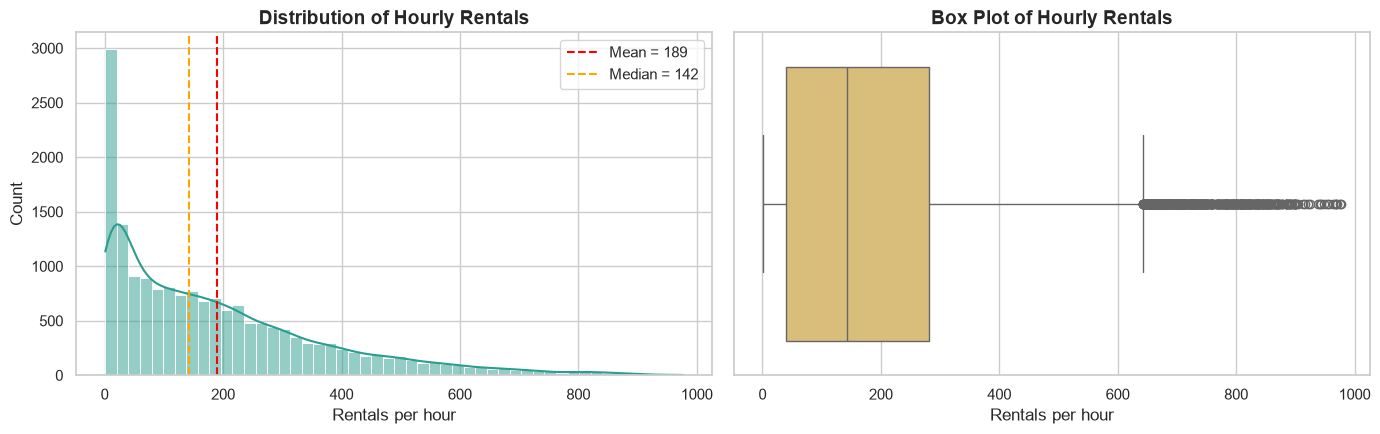

Skewness: 1.28
count    17379.0
mean       189.5
std        181.4
min          1.0
25%         40.0
50%        142.0
75%        281.0
max        977.0


In [10]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

sns.histplot(df["cnt"], bins=50, kde=True, ax=axes[0], color="#2A9D8F")
axes[0].axvline(df["cnt"].mean(), color="red", ls="--", label=f"Mean = {df['cnt'].mean():.0f}")
axes[0].axvline(df["cnt"].median(), color="orange", ls="--", label=f"Median = {df['cnt'].median():.0f}")
axes[0].set_title("Distribution of Hourly Rentals")
axes[0].set_xlabel("Rentals per hour")
axes[0].legend()

sns.boxplot(x=df["cnt"], ax=axes[1], color="#E9C46A")
axes[1].set_title("Box Plot of Hourly Rentals")
axes[1].set_xlabel("Rentals per hour")

plt.tight_layout()
plt.show()

print(f"Skewness: {df['cnt'].skew():.2f}")
print(df["cnt"].describe().round(1).to_string())

## 7️⃣ Time-Based Analysis

### 7.1 Year-over-Year Growth

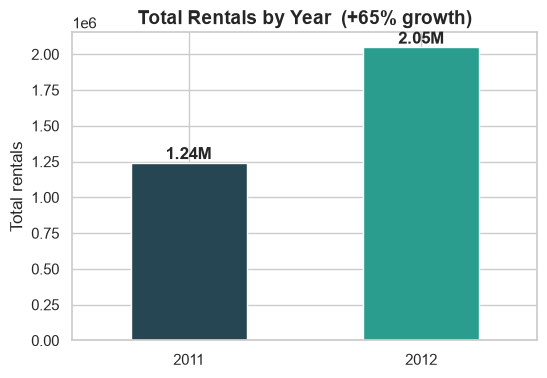

In [11]:
yearly = df.groupby("year")["cnt"].sum()
growth = yearly.pct_change().iloc[-1] * 100

ax = yearly.plot(kind="bar", color=["#264653", "#2A9D8F"], figsize=(6, 4), rot=0)
for i, v in enumerate(yearly):
    ax.text(i, v, f"{v/1e6:.2f}M", ha="center", va="bottom", fontweight="bold")
ax.set_title(f"Total Rentals by Year  (+{growth:.0f}% growth)")
ax.set_ylabel("Total rentals")
ax.set_xlabel("")
plt.show()

### 7.2 Daily Rentals Over Time

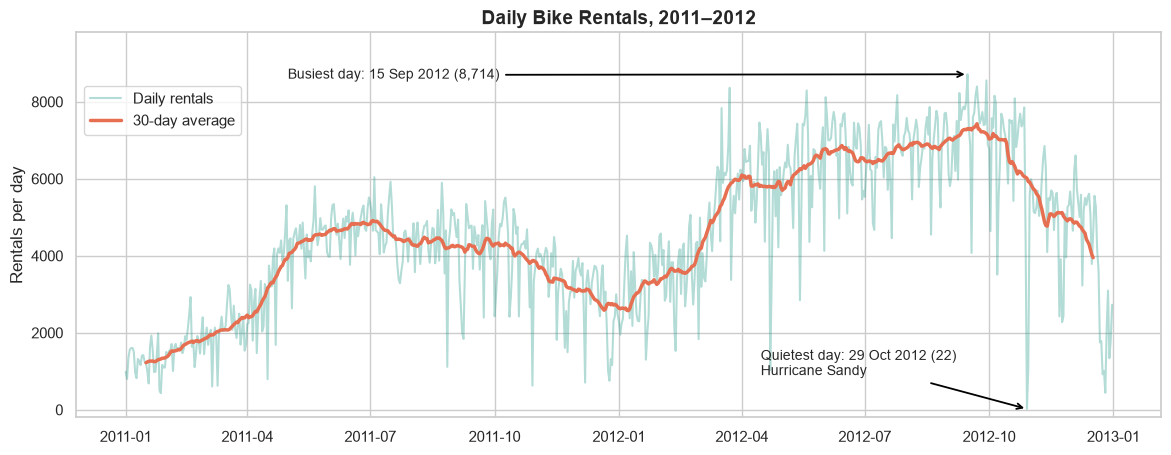

In [12]:
daily = df.groupby("dteday")["cnt"].sum()
rolling = daily.rolling(30, center=True).mean()

plt.figure(figsize=(14, 5))
plt.plot(daily.index, daily.values, alpha=0.35, color="#2A9D8F", label="Daily rentals")
plt.plot(rolling.index, rolling.values, color="#E76F51", lw=2.5, label="30-day average")

top, low = daily.idxmax(), daily.idxmin()
arrow = dict(arrowstyle="->", color="black", lw=1.3)
plt.annotate(f"Busiest day: {top:%d %b %Y} ({daily.max():,})",
             xy=(top, daily.max()), xytext=(pd.Timestamp("2011-05-01"), 8600),
             arrowprops=arrow, fontsize=10)
plt.annotate(f"Quietest day: {low:%d %b %Y} ({daily.min():,})\nHurricane Sandy",
             xy=(low, daily.min()), xytext=(pd.Timestamp("2012-04-15"), 900),
             arrowprops=arrow, fontsize=10)
plt.ylim(-200, 9800)
plt.title("Daily Bike Rentals, 2011–2012")
plt.ylabel("Rentals per day")
plt.legend(loc="upper left", bbox_to_anchor=(0, 0.88))
plt.show()

### 7.3 Season & Month

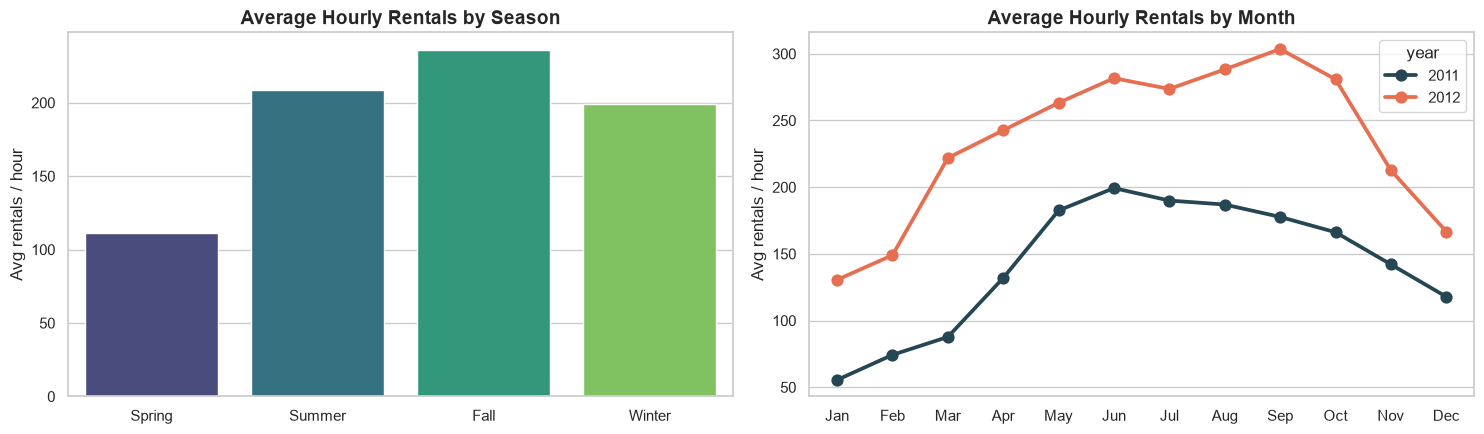

,avg_rentals_per_hour
season_name,
Spring,111.1
Summer,208.3
Fall,236.0
Winter,198.9


In [13]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))

sns.barplot(data=df, x="season_name", y="cnt", order=SEASONS, ax=axes[0],
            palette="viridis", errorbar=None)
axes[0].set_title("Average Hourly Rentals by Season")
axes[0].set_xlabel(""); axes[0].set_ylabel("Avg rentals / hour")

sns.pointplot(data=df, x="month_name", y="cnt", hue="year", order=MONTHS, ax=axes[1],
              palette=["#264653", "#E76F51"], errorbar=None)
axes[1].set_title("Average Hourly Rentals by Month")
axes[1].set_xlabel(""); axes[1].set_ylabel("Avg rentals / hour")

plt.tight_layout()
plt.show()

df.groupby("season_name")["cnt"].mean().reindex(SEASONS).round(1).to_frame("avg_rentals_per_hour")

### 7.4 Hour of the Day — the Most Important Pattern

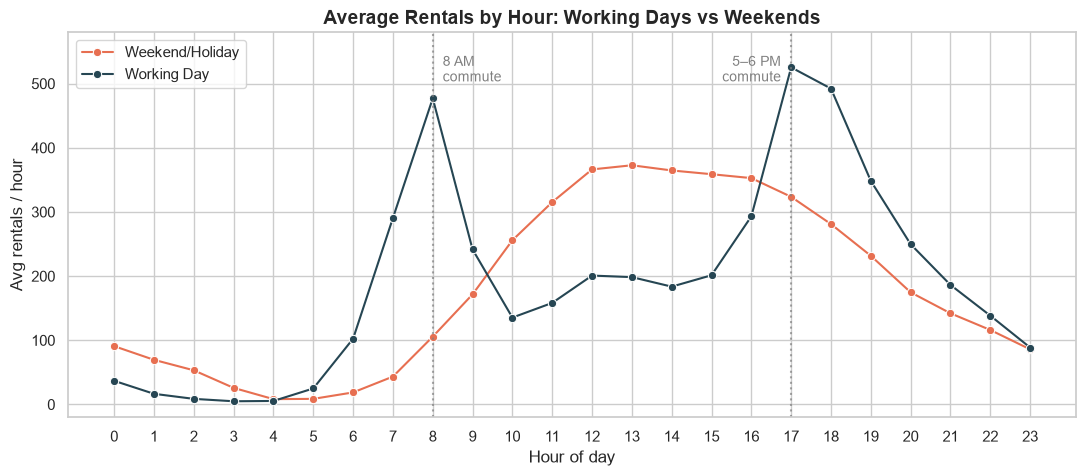

In [14]:
plt.figure(figsize=(13, 5))
sns.lineplot(data=df, x="hr", y="cnt", hue="day_type", marker="o", errorbar=None,
             palette={"Working Day": "#264653", "Weekend/Holiday": "#E76F51"})
for h, label, ha, dx in [(8, "8 AM\ncommute", "left", 0.25), (17, "5–6 PM\ncommute", "right", -0.25)]:
    plt.axvline(h, color="grey", ls=":", alpha=0.7)
    plt.text(h + dx, 545, label, fontsize=10, color="grey", va="top", ha=ha)
plt.title("Average Rentals by Hour: Working Days vs Weekends")
plt.xlabel("Hour of day")
plt.ylabel("Avg rentals / hour")
plt.xticks(range(24))
plt.legend(title="", loc="upper left")
plt.ylim(-20, 580)
plt.show()

### 7.5 Heatmap: Hour × Day of Week

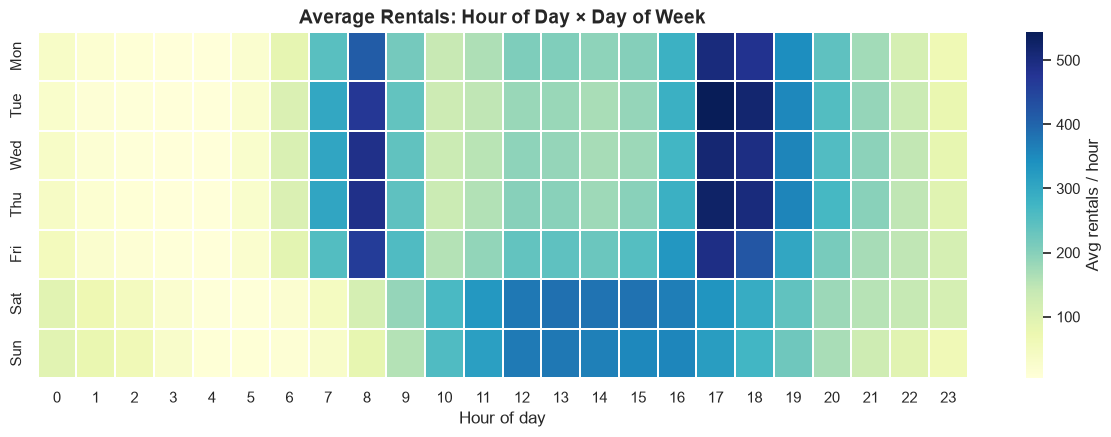

In [15]:
heat = df.pivot_table(index="day_name", columns="hr", values="cnt", aggfunc="mean").reindex(DAYS)

plt.figure(figsize=(15, 4.5))
sns.heatmap(heat, cmap="YlGnBu", linewidths=0.3, cbar_kws={"label": "Avg rentals / hour"})
plt.title("Average Rentals: Hour of Day × Day of Week")
plt.xlabel("Hour of day")
plt.ylabel("")
plt.show()

## 8️⃣ Weather Analysis


### 8.1 Weather Situation

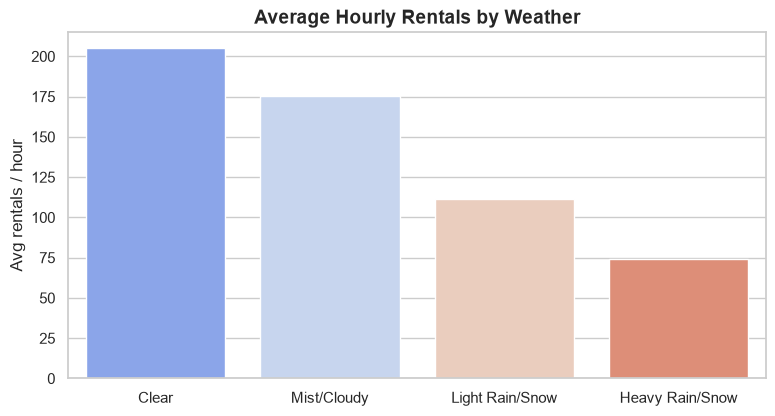

,avg_rentals,hours,share_of_hours_%
weather,,,
Clear,204.9,11413,65.7
Mist/Cloudy,175.2,4544,26.1
Light Rain/Snow,111.6,1419,8.2
Heavy Rain/Snow,74.3,3,0.0


In [16]:
weather_stats = (df.groupby("weather")["cnt"]
                   .agg(avg_rentals="mean", hours="count")
                   .reindex(WEATHER).round(1))
weather_stats["share_of_hours_%"] = (weather_stats["hours"] / len(df) * 100).round(1)

fig, ax = plt.subplots(figsize=(9, 4.5))
sns.barplot(data=df, x="weather", y="cnt", order=WEATHER, palette="coolwarm", errorbar=None, ax=ax)
ax.set_title("Average Hourly Rentals by Weather")
ax.set_xlabel(""); ax.set_ylabel("Avg rentals / hour")
plt.show()

weather_stats

### 8.2 Temperature, Humidity and Wind

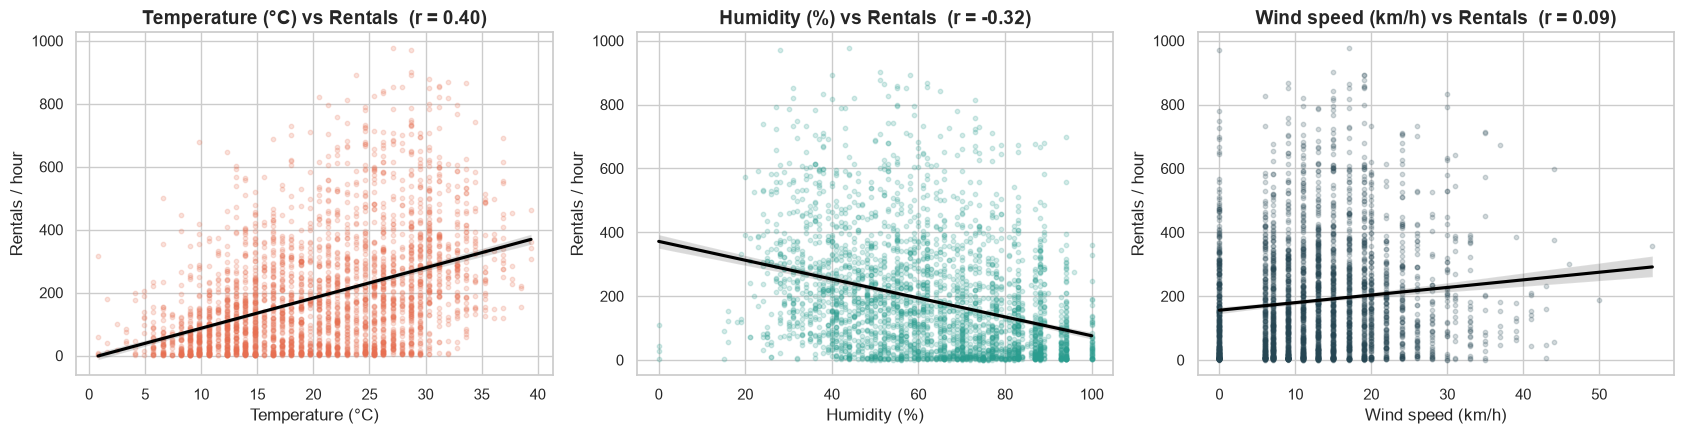

In [17]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
sample = df.sample(3000, random_state=42)    # sample so the scatter isn't overcrowded

for ax, col, label, color in zip(axes,
        ["temp_c", "humidity", "wind_kmh"],
        ["Temperature (°C)", "Humidity (%)", "Wind speed (km/h)"],
        ["#E76F51", "#2A9D8F", "#264653"]):
    sns.regplot(data=sample, x=col, y="cnt", ax=ax, scatter_kws={"alpha": 0.2, "s": 10},
                line_kws={"color": "black"}, color=color)
    r = df[col].corr(df["cnt"])
    ax.set_title(f"{label} vs Rentals  (r = {r:.2f})")
    ax.set_xlabel(label); ax.set_ylabel("Rentals / hour")

plt.tight_layout()
plt.show()

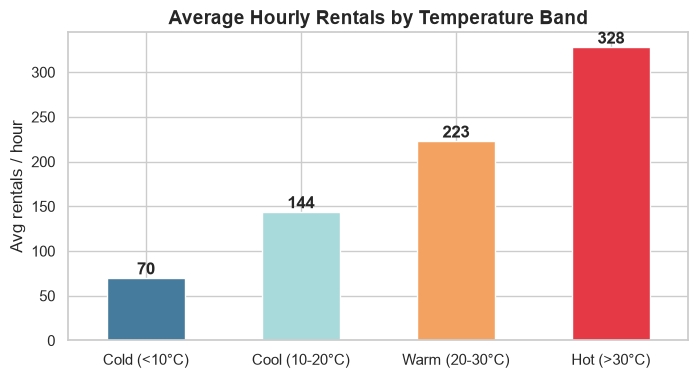

In [18]:
temp_stats = df.groupby("temp_band")["cnt"].mean().round(0)

ax = temp_stats.plot(kind="bar", color=["#457B9D", "#A8DADC", "#F4A261", "#E63946"],
                     figsize=(8, 4), rot=0)
for i, v in enumerate(temp_stats):
    ax.text(i, v, f"{v:.0f}", ha="center", va="bottom", fontweight="bold")
ax.set_title("Average Hourly Rentals by Temperature Band")
ax.set_xlabel(""); ax.set_ylabel("Avg rentals / hour")
plt.show()

## 9️⃣ Casual vs Registered Users

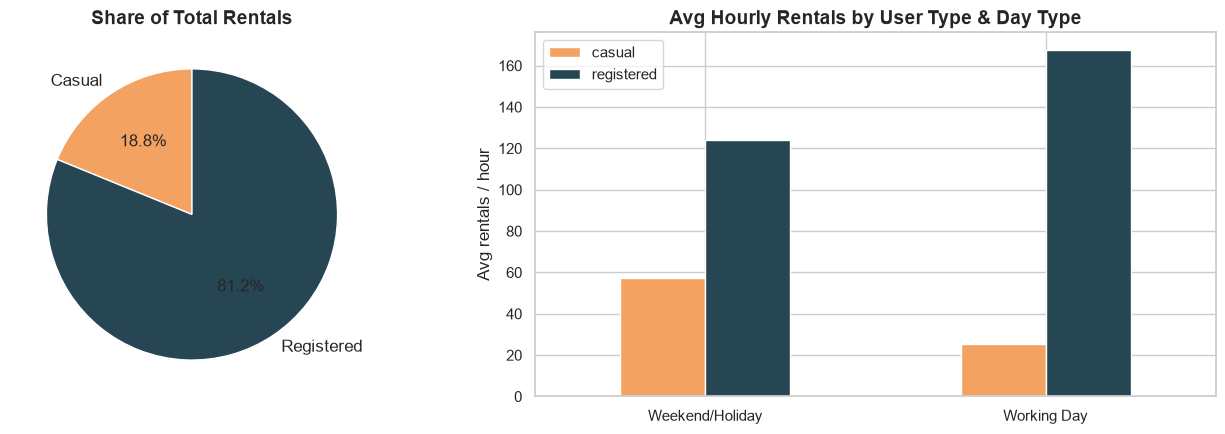

,casual,registered
day_type,,
Weekend/Holiday,57.4,124.0
Working Day,25.6,167.6


In [19]:
totals = df[["casual", "registered"]].sum()

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
axes[0].pie(totals, labels=["Casual", "Registered"], autopct="%1.1f%%",
            colors=["#F4A261", "#264653"], startangle=90, textprops={"fontsize": 12})
axes[0].set_title("Share of Total Rentals")

user_day = df.groupby("day_type")[["casual", "registered"]].mean()
user_day.plot(kind="bar", ax=axes[1], color=["#F4A261", "#264653"], rot=0)
axes[1].set_title("Avg Hourly Rentals by User Type & Day Type")
axes[1].set_xlabel(""); axes[1].set_ylabel("Avg rentals / hour")

plt.tight_layout()
plt.show()

user_day.round(1)

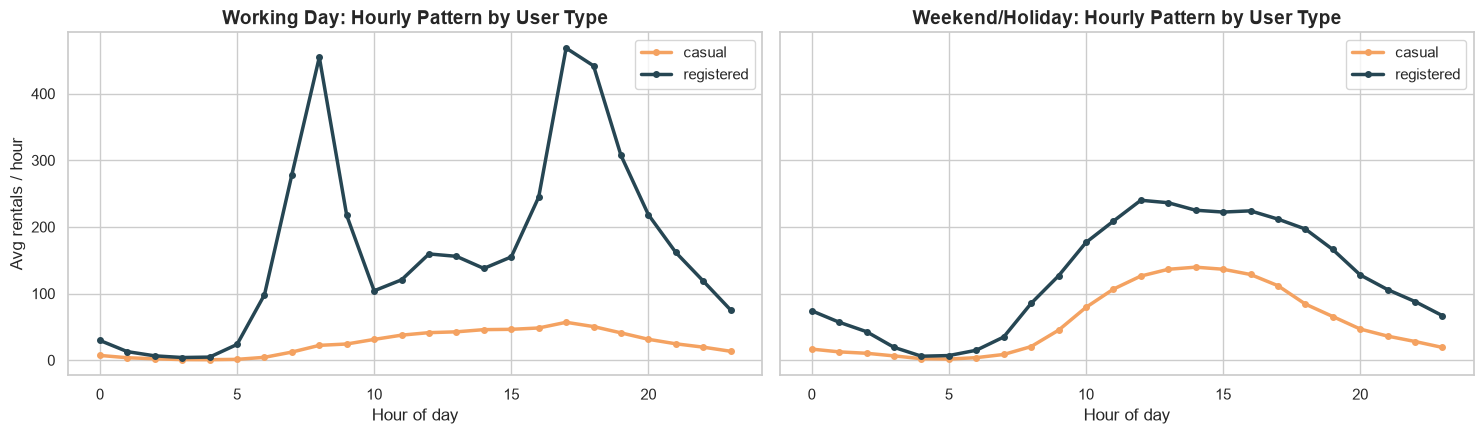

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5), sharey=True)
for ax, dt in zip(axes, ["Working Day", "Weekend/Holiday"]):
    sub = df[df["day_type"] == dt].groupby("hr")[["casual", "registered"]].mean()
    sub.plot(ax=ax, color=["#F4A261", "#264653"], lw=2.5, marker="o", ms=4)
    ax.set_title(f"{dt}: Hourly Pattern by User Type")
    ax.set_xlabel("Hour of day"); ax.set_ylabel("Avg rentals / hour")
plt.tight_layout()
plt.show()

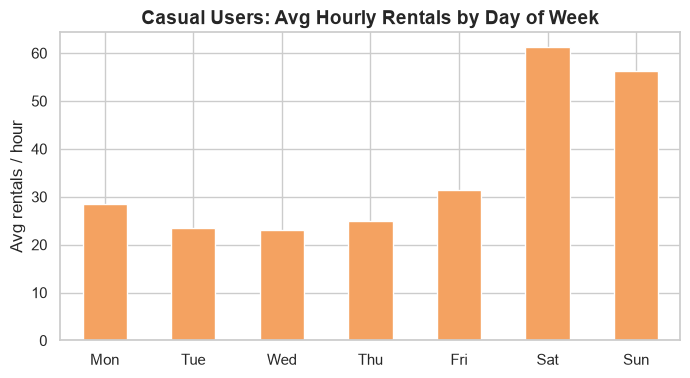

In [21]:
casual_by_day = df.groupby("day_name")["casual"].mean().reindex(DAYS)
ax = casual_by_day.plot(kind="bar", color="#F4A261", figsize=(8, 4), rot=0)
ax.set_title("Casual Users: Avg Hourly Rentals by Day of Week")
ax.set_xlabel(""); ax.set_ylabel("Avg rentals / hour")
plt.show()

## 🔟 Holidays & Working Days

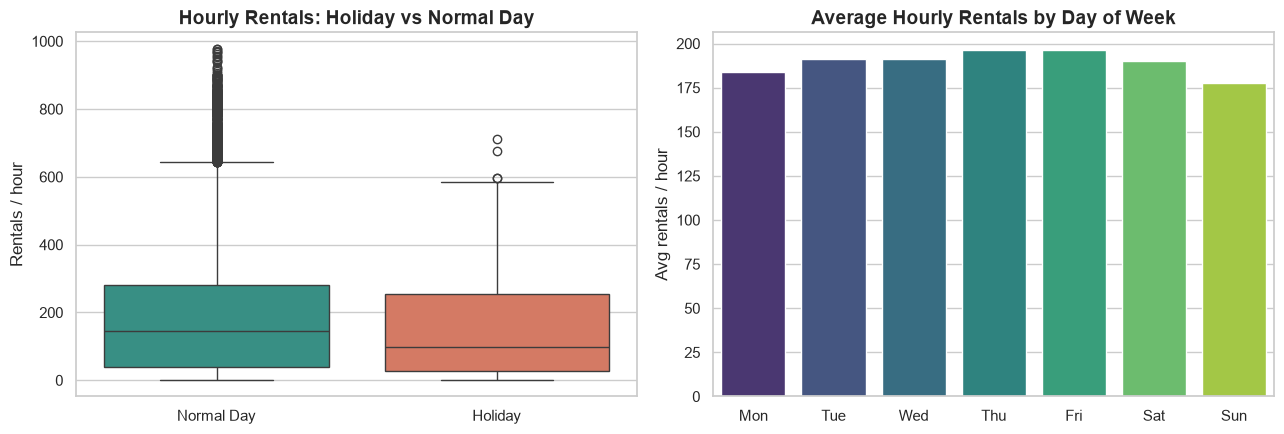

holiday
Holiday       156.9
Normal Day    190.4


In [22]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

sns.boxplot(data=df, x=df["holiday"].map({0: "Normal Day", 1: "Holiday"}), y="cnt",
            ax=axes[0], palette=["#2A9D8F", "#E76F51"])
axes[0].set_title("Hourly Rentals: Holiday vs Normal Day")
axes[0].set_xlabel(""); axes[0].set_ylabel("Rentals / hour")

sns.barplot(data=df, x="day_name", y="cnt", order=DAYS, ax=axes[1],
            palette="viridis", errorbar=None)
axes[1].set_title("Average Hourly Rentals by Day of Week")
axes[1].set_xlabel(""); axes[1].set_ylabel("Avg rentals / hour")

plt.tight_layout()
plt.show()

print(df.groupby(df["holiday"].map({0: "Normal Day", 1: "Holiday"}))["cnt"].mean().round(1).to_string())

## 1️⃣1️⃣ Correlation Analysis

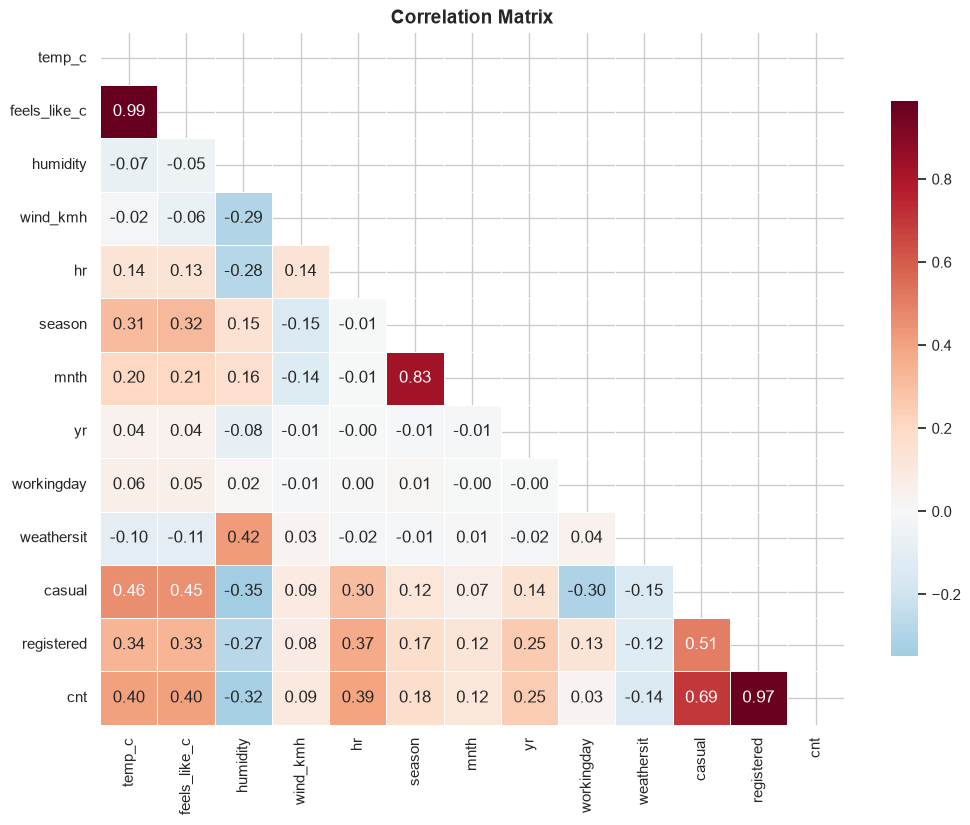

In [23]:
corr_cols = ["temp_c", "feels_like_c", "humidity", "wind_kmh", "hr",
             "season", "mnth", "yr", "workingday", "weathersit",
             "casual", "registered", "cnt"]
corr = df[corr_cols].corr()

plt.figure(figsize=(12, 9))
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, mask=mask, annot=True, fmt=".2f", cmap="RdBu_r", center=0,
            linewidths=0.5, cbar_kws={"shrink": 0.8})
plt.title("Correlation Matrix")
plt.show()

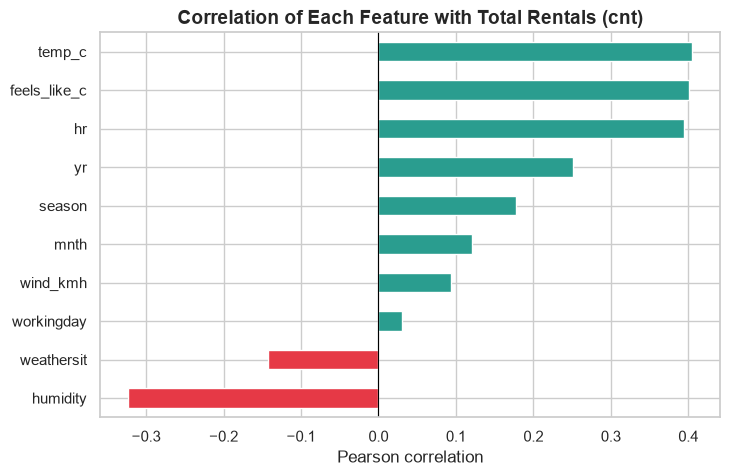

In [24]:
corr["cnt"].drop(["cnt", "casual", "registered"]).sort_values().plot(
    kind="barh", figsize=(8, 5),
    color=[("#E63946" if v < 0 else "#2A9D8F")
           for v in corr["cnt"].drop(["cnt", "casual", "registered"]).sort_values()])
plt.title("Correlation of Each Feature with Total Rentals (cnt)")
plt.xlabel("Pearson correlation")
plt.axvline(0, color="black", lw=0.8)
plt.show()

## 1️⃣2️⃣ Outlier Analysis (IQR Method)

In [25]:
q1, q3 = df["cnt"].quantile([0.25, 0.75])
iqr = q3 - q1
upper = q3 + 1.5 * iqr
outliers = df[df["cnt"] > upper]

print(f"Q1 = {q1:.0f}, Q3 = {q3:.0f}, IQR = {iqr:.0f}")
print(f"Upper fence = {upper:.1f}")
print(f"Outlier hours: {len(outliers)} ({len(outliers)/len(df)*100:.1f}% of data)\n")

print("When do these 'outliers' happen?")
print(outliers["hr"].value_counts().head(5).rename("count").to_frame().T)
print(outliers["day_type"].value_counts().to_string())

Q1 = 40, Q3 = 281, IQR = 241
Upper fence = 642.5
Outlier hours: 505 (2.9% of data)

When do these 'outliers' happen?
hr      17   18   8   13  12
count  153  129  127  23  17
day_type
Working Day        414
Weekend/Holiday     91
